In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
try:
    import geopandas as gpd
except ImportError:
    print("Geopandas is not installed. Attempting to install it now...")
    !pip install geopandas
    import geopandas as gpd

DO_WITHIN_BUFF = False


# Geospatial Basics

<b>Note on Data:</b> I am dropping the neighborhoods data from this dataset because we will find it later, using spatial data. 

In [2]:
bylaw_data_url = "https://jrssbcrsefilesnait.blob.core.windows.net/3950data1/Bylaw_Complaint_Details_20261119.csv"
save_file_path = "data/zz_bylaw_complaints.csv"

# Check if we have the file, if not, download it. 
# the zz preface ensures it'll not be included in any github actions
if not os.path.exists(save_file_path):
    print("Downloading file...")
    df = pd.read_csv(bylaw_data_url)
    df.to_csv(save_file_path, index=False)
else:
    print("File already exists, loading from disk...")
    df = pd.read_csv(save_file_path)
df.drop(columns=['Neighbourhood', 'Neighbourhood ID', 'Count'], inplace=True)
df["Was Cannabis Involved"] = df["Was Cannabis Involved"].map({"Yes": 1, "No": 0})
df["Officer Initiated"] = df["Officer Initiated"].map({"Y": 1, "N": 0})
df.head()

File already exists, loading from disk...


,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,Latitude,Longitude,Location
0,5028615873227154,2011,03-Mar,"Mar 04, 2011",Other,General,0,0,Completed,94 STREET NW,53.576617,-113.485788,"(53.57661685027798, -113.48578832240503)"
1,2738089933835615,2021,05-May,"May 19, 2021",Other,Parking,0,1,Completed,51A AVENUE NW,53.488778,-113.547696,"(53.48877809550821, -113.5476961841882)"
2,1278526920564440,2012,08-Aug,"Aug 30, 2012",Property - Nuisance,Weeds,0,0,Completed,118 STREET NW,53.584944,-113.525097,"(53.58494357977947, -113.52509672020835)"
3,624062632081946,2015,05-May,"May 19, 2015",Property - Nuisance,Weeds,0,0,Completed,59 STREET SW,53.422638,-113.431093,"(53.42263751525145, -113.43109261133989)"
4,424925098208313600,2016,06-Jun,"Jun 03, 2016",Other,General,0,0,Completed,99 AVENUE NW,53.535659,-113.631105,"(53.5356590934005, -113.63110529189252)"


## Geometries

The first thing that we can do is to define the geometry for our dataset. The 'geometry' column is a special column that contains the geometric info for whatever the data represents. For ours, we have a list of bylaw infractions from the city, so we want the geometry column to be the location of the infraction. In other situations it might be the area of a neighborhood, or the location of a business, or the land of a park. Basicially whatever the "mapped thing" is for this dataset. 

Note that we aren't strictly limited to one geometric thing per row, we can have as many columsn holding geometric data as we want, the 'geometry' column is the default "shape" of the row of data, and if we map it, that's what we get. 

### Creating Geometry Columns

Our data will have something that defines it's spatial data, generally either latitude/longitude, a "polygon" column representing a region, or a pre-defined "point" that may or may not be automatically interpreted correctly. Our data has a "location" column that has the pont information, but we'd need to do some work to make geopandas understand it, it will give an error if fed that column as geometry directly. Instead, we can use the latitude and longitude columns to create a new geometry column.

### Coordinate Systems

The details of this are beyond what we care about, but there are basically several different ways encode spatial data, and they are not all compatible with each other. We can think of these kind of like different map projections - they all show the same base information, but represent it differently. This is something that comes from whover made the dataset, for ours, I read that LL-WGS84 is the system used from the data dictionary. 

One important note is that there are two different types of coordinate systems, geographic and projected. Geographic coordinate systems use latitude and longitude to define locations on the earth's surface, while projected coordinate systems use a flat, two-dimensional plane to represent the earth's surface. For this example we'll use two common systems, LL-WGS84 (EPSG:4326) and Web Mercator (EPSG:3857). The differences become important when we are doing calculations, like distances - for accurate values we want to use one of the ones that works in "flat meters" rather than "degrees of latitude/longitude". The to_crs() function can be used to convert between coordinate systems as needed.  

For things to work accurately, we need to tell our data what coordinate system it is using. I looked up the EPSG code for LL-WGS84, and it is 4326. So we will use that to define our geometry column.

In [3]:
df.head(5)

,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,Latitude,Longitude,Location
0,5028615873227154,2011,03-Mar,"Mar 04, 2011",Other,General,0,0,Completed,94 STREET NW,53.576617,-113.485788,"(53.57661685027798, -113.48578832240503)"
1,2738089933835615,2021,05-May,"May 19, 2021",Other,Parking,0,1,Completed,51A AVENUE NW,53.488778,-113.547696,"(53.48877809550821, -113.5476961841882)"
2,1278526920564440,2012,08-Aug,"Aug 30, 2012",Property - Nuisance,Weeds,0,0,Completed,118 STREET NW,53.584944,-113.525097,"(53.58494357977947, -113.52509672020835)"
3,624062632081946,2015,05-May,"May 19, 2015",Property - Nuisance,Weeds,0,0,Completed,59 STREET SW,53.422638,-113.431093,"(53.42263751525145, -113.43109261133989)"
4,424925098208313600,2016,06-Jun,"Jun 03, 2016",Other,General,0,0,Completed,99 AVENUE NW,53.535659,-113.631105,"(53.5356590934005, -113.63110529189252)"


Mapping using CRS: EPSG:4326


<Axes: >

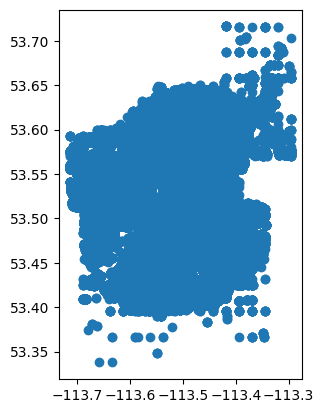

In [4]:
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df['Longitude'], df['Latitude']))
gdf = gdf.set_crs(epsg=4326)  # Set the coordinate reference system to WGS84
gdf.dropna(subset=['geometry'], inplace=True)  # Drop rows where geometry is NaN
print("Mapping using CRS:", gdf.crs)
gdf.plot()

### More Mapping

That plot of the points looks pretty bad, we don't have any map info other than the locations of the dots. We can add a basemap to the plot to make it look better. To do this, we will use the contextily library, which is a library that adds basemaps to geopandas plots.

In [5]:
try:
    import contextily as ctx
except ImportError:
    print("Contextily is not installed. Attempting to install it now...")
    !pip install contextily
    import contextily as ctx

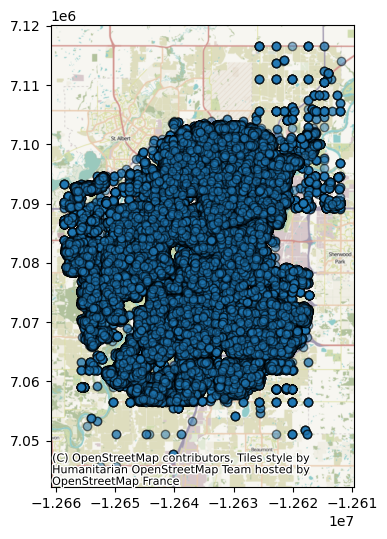

In [6]:
gdf_mercator = gdf.to_crs(epsg=3857)
ax = gdf_mercator.plot(alpha=0.5, edgecolor='k', figsize=(6, 6))
ctx.add_basemap(ax)

## Adding Layers Manually

In [7]:
gdf_hoods = gpd.read_file("data/edmontonHoods.kml")
gdf.set_geometry("geometry")
gdf.set_crs(epsg=4326, inplace=True)  # Ensure the CRS is set for gdf
gdf_hoods.head()

,Name,description,timestamp,begin,end,altitudeMode,tessellate,extrude,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,geometry
0,ABBOTTSFIELD,"Abbottsfield was once owned by E.F. Carey, one...",NaT,NaT,NaT,None,-1,0,-1,NaN,None,2010,Abbottsfield,,,"MULTIPOLYGON (((-113.38763 53.57613, -113.3888..."
1,ALBANY,,NaT,NaT,NaT,None,-1,0,-1,NaN,None,3460,Albany,,,"MULTIPOLYGON (((-113.56025 53.6316, -113.56227..."
2,ALBERTA AVENUE,One of the city's older residential neighbourh...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,1010,Alberta Avenue,,,"MULTIPOLYGON (((-113.49226 53.57662, -113.4922..."
3,ALBERTA PARK INDUSTRIAL,This non-residential neighbourhood is largely ...,NaT,NaT,NaT,None,-1,0,-1,NaN,None,4010,Alberta Park Industrial,,,"MULTIPOLYGON (((-113.59041 53.56654, -113.5904..."
4,ALDERGROVE,"Planned in the 1970s, this area's multi-family...",NaT,NaT,NaT,None,-1,0,-1,NaN,None,4020,Aldergrove,,,"MULTIPOLYGON (((-113.65209 53.5195, -113.65209..."


<Axes: >

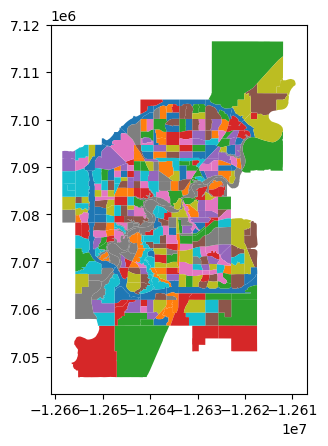

In [8]:
gdf_hoods_mercator = gdf_hoods.to_crs(epsg=3857)
gdf_hoods_mercator.plot("Name")

And together. 

<Axes: >

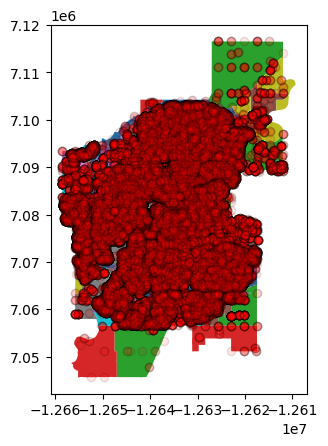

In [9]:
fig, ax = plt.subplots()
gdf_hoods_mercator.plot("Name", ax=ax)
gdf_mercator.plot(ax=ax, alpha=0.1, edgecolor='k', color='red')

## Spatial Joins

We can use the data plotted on the map above to do a join, a spatial join. The difference in a spatial join is that rather than having some key value to join on, we are joining based on the spatial relationship between the two datasets. The spatial processing in geopandas will automatically do the math for the join for us. 

These spatial joins replace the key with some spatial calculation, typically something like what we'll do, is this point in this neighborhood? So, we can effectively add the neighborhood column to the original dataset by looking up which neighborhood geometry contains the point geometry for each row in the original dataset.

<b>Note:</b> The spatial join will only work correctly if both datasets are in the same coordinate system. We also lose the right side of the join's geometry column when geopandas does the join, so the loop is just to restore it. 

### Keep 'em Separated

In most cases, it is easier to keep the datasets separate if we are dealing with multiple spatial datasets, and just join as needed. The geopandas dataframe is generally setup to default to one geometry column being the "main thing". We can construct a dataset with many spatial columns, but it is likely to be more annoying than having separate dataframes. 

In [10]:
df_w_hoods = gpd.sjoin(gdf_mercator, gdf_hoods_mercator, how="left", predicate='within')
hood_geometries = df_w_hoods["index_right"].map(gdf_hoods_mercator.geometry)
df_w_hoods["hood_geometry"] = gpd.GeoSeries(
    hood_geometries.tolist(),
    index=df_w_hoods.index,
    crs=gdf_hoods_mercator.crs,
)
df_w_hoods.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 689827 entries, 0 to 689704
Data columns (total 31 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   Row ID                 689827 non-null  object        
 1   Year                   689827 non-null  int64         
 2   Month                  689827 non-null  object        
 3   Date Created           689827 non-null  object        
 4   Complaint Category     689827 non-null  object        
 5   Type of Complaint      689827 non-null  object        
 6   Was Cannabis Involved  689827 non-null  int64         
 7   Officer Initiated      689827 non-null  int64         
 8   Infraction Status      689827 non-null  object        
 9   Full Name of Street    689827 non-null  object        
 10  Latitude               689827 non-null  float64       
 11  Longitude              689827 non-null  float64       
 12  Location               689827 non-null  o

<Axes: >

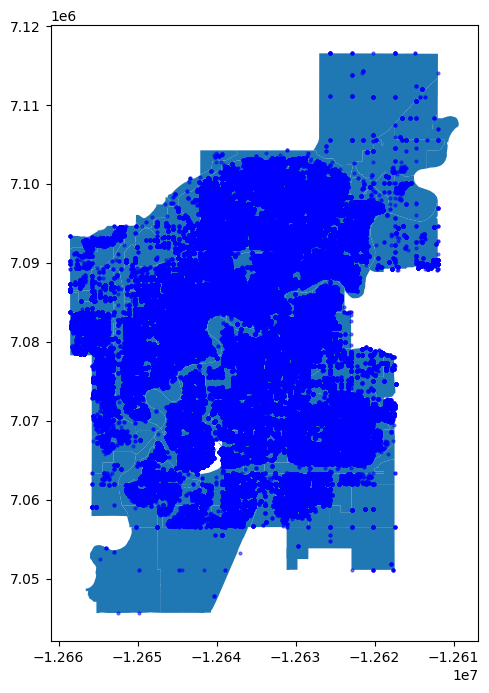

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))
df_w_hoods["hood_geometry"].dropna().drop_duplicates().plot(ax=ax)
df_w_hoods["geometry"].plot(ax=ax, color="blue", markersize=4, alpha=0.5)

## Modelling

Ok, let's use this to make some predictive models. 

### Spatial Features

We can use the latitude and longitude directly, they are just numbers, but in most cases these wouldn't make good features. They would basically give us the E/W and N/S position of each incident, but I doubt that's super useful. If we were building a model to aim artillery shots, then having latitude and longitude may be very useful, but in most cases, we want to *construct* new features from the spatial data. 

In most cases, the types of things we'd create from spatial data are things like:
<ul>
    <li> Distance to some point of interest.</li>
    <li> Number of points within some distance/region.</li>
    <li> Whether the point is within some region.</li>
    <li> Closest neighbor distance.</li>
</ul>

Now, our specific set of examples here are strictly for demonstration purposes, these probably won't result in an incredible model, but they will show how to use spatial data to create features.


### Predict Cannabis

One of the values in our dataset is a binary value on if the infraction involved cannabis or not. We can use this as a target variable for a classification model.

### Baseline Model

For the baseline model, I'll use the latitude and longitude directly, and see how well that does. Note that I don't think these 311 calls are the easiest thing to predict in the best of times. 

I'm also going to define a subset of features to use for all of these models. In reality, we'd want to do some tuning and testing here, but we won't do that outside of spatial things. 

In [12]:
df_w_hoods["Officer Initiated"].value_counts()

Officer Initiated
0    509207
1    180620
Name: count, dtype: int64

In [13]:
predCol = "Officer Initiated"

numFeatures = ["Latitude", "Longitude", "Year"]
catFeatures = ["Month", "Complaint Category", "Type of Complaint"]
pred_cols = numFeatures + catFeatures
df_w_hoods = df_w_hoods.dropna(subset=pred_cols)  # Drop rows with NaN in any of the predictor columns

y1 = df_w_hoods[predCol]
X1 = df_w_hoods[pred_cols]
print("Features shape:", X1.shape)
print("Target shape:", y1.shape)

Features shape: (689827, 6)
Target shape: (689827,)


In [14]:
def makePipe(numFeatLabels, catFeatLabels, doRegression=False):
    # Preprocessing for numerical data
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Preprocessing for categorical data
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    # Combine preprocessing steps
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numFeatLabels),
            ('cat', categorical_transformer, catFeatLabels)
        ])

    # Create the pipeline with a classifier
    if doRegression:
        clf = Pipeline(steps=[('preprocessor', preprocessor),
                              ('regressor', LinearRegression())])
    else:
        clf = Pipeline(steps=[('preprocessor', preprocessor),
                              ('classifier', LogisticRegression(max_iter=1000))])
    
    return clf

Baseline model accuracy: 0.7571


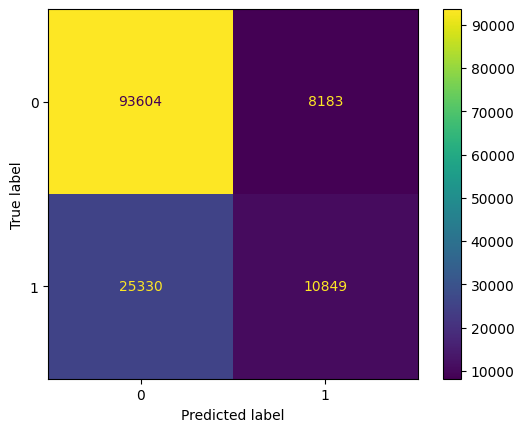

In [15]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(X1, y1, test_size=0.2)

pipe1 = makePipe(numFeatures, catFeatures)

pipe1.fit(X_train1, y_train1)
predictions1 = pipe1.predict(X_test1)
accuracy1 = (predictions1 == y_test1).mean()
print(f"Baseline model accuracy: {accuracy1:.4f}")
# confusion matrix
cm1 = confusion_matrix(y_test1, predictions1)
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm1, display_labels=pipe1.classes_)
disp1.plot()

### Try Some Variations

Now we can try to make some models using spatial features and try using them in models. 

This specific dataset doesn't make for the most dramatic results, but the processes are the same no matter the data. 

#### Distance from Police

We can use the police station locations to create a feature that is the distance from each infraction to the nearest police station. 

In [16]:
stations = pd.read_csv("data/Police_Stations.csv")
stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations["LONGITUDE"], stations["LATITUDE"]),
    crs="EPSG:4326",
)
stations = stations.dropna(subset=['geometry'])  # Drop rows where geometry is NaN
stations.to_crs(epsg=3857, inplace=True)  # Convert to Web Mercator for mapping
stations.head()

,NAME,ADDRESS,LATITUDE,LONGITUDE,LOCATION,Geometry Point,geometry
0,POLICE SERVICES - NORTHEAST DIVISION,14203 - 50 STREET NW,53.605040,-113.417301,"(53.60503991263262, -113.41730142003281)",POINT (-113.41730142003281 53.60503991263262),POINT (-12625556.241 7095707.618)
1,ROYAL CANADIAN MOUNTED POLICE,11136 - 109 STREET NW,53.559845,-113.509119,"(53.55984492708671, -113.50911929739945)",POINT (-113.50911929739945 53.55984492708671),POINT (-12635777.361 7087233.008)
2,POLICE SERVICES - WEST DIVISION,16505 - 100 AVENUE NW,53.538808,-113.606742,"(53.538808087195235, -113.60674227242592)",POINT (-113.60674227242592 53.538808087195235),POINT (-12646644.7 7083291.432)
3,RCMP K DIVISION,11136 - 109 STREET NW,53.559845,-113.509119,"(53.55984492708671, -113.50911929739945)",POINT (-113.50911929739945 53.55984492708671),POINT (-12635777.361 7087233.008)
4,POLICE SERVICES - SOUTHEAST DIVISION,104 - YOUVILLE DRIVE EAST NW,53.460001,-113.426714,"(53.46000050776202, -113.42671444062009)",POINT (-113.42671444062009 53.46000050776202),POINT (-12626604.094 7068543.007)


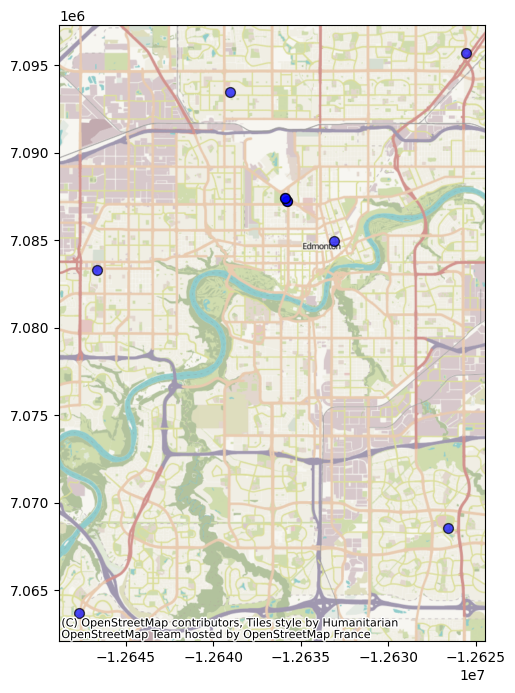

In [17]:
ax = stations.plot(color='blue', markersize=50, alpha=0.7, edgecolor='k', figsize=(8, 8))
ctx.add_basemap(ax)

### Feature Construction - Distance

Distance is probably the most common type of feature that we would construct from spatial data. We can use the distance between points, or the distance from a point to some other location like the city center, a police station, or another neighborhood. As long as we have geometries defined, we can use the distance function to calculate the distance between two geometries. 

We can make a simple function to calculate the distances, as long as our datasets have their geometries set and tehy are in the same coordinate system, we need to do very little. If we need to use some specific location to calculate from, we can just create a new point or polygon geometry and use that as the "other" dataset.

The crs system used for the distance calculations is important, we need to make sure that both datasets are in the same coordinate system, and that the coordinate system is one that makes sense for distance calculations. The default crs for geopandas is EPSG:4326, which is a geographic coordinate system, and not a projected coordinate system. This means that the units are in degrees, and not in meters. For distance calculations, we want to use a projected coordinate system, so we will convert our datasets to EPSG:3857, which is a projected coordinate system that uses meters as units.

In [18]:
def getClosestStationDistance(row, stations_gdf):
    if row.geometry is None or row.geometry.is_empty:
        return None
    distances = stations_gdf.distance(row.geometry)
    smallest_distance = distances.min()
    return smallest_distance

# Add a new column for the closest station distance and name
df_w_hoods.to_crs(epsg=3857, inplace=True)  # Ensure the CRS is set for df_w_hoods
df_w_hoods["closest_station_distance"] = df_w_hoods.apply(getClosestStationDistance, axis=1, stations_gdf=stations)

df_w_hoods.head()

,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,...,extrude,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,hood_geometry,closest_station_distance
0,5028615873227154,2011,03-Mar,"Mar 04, 2011",Other,General,0,0,Completed,94 STREET NW,...,0.0,-1.0,NaN,None,1010,Alberta Avenue,,,"MULTIPOLYGON (((-12633900.296 7090376.857, -12...",4014.757186
1,2738089933835615,2021,05-May,"May 19, 2021",Other,Parking,0,1,Completed,51A AVENUE NW,...,0.0,-1.0,NaN,None,5260,Lansdowne,,,"MULTIPOLYGON (((-12640969.356 7074220.835, -12...",11442.340253
2,1278526920564440,2012,08-Aug,"Aug 30, 2012",Property - Nuisance,Weeds,0,0,Completed,118 STREET NW,...,0.0,-1.0,NaN,None,3070,Calder,,,"MULTIPOLYGON (((-12639161.377 7091746.466, -12...",2154.298789
3,624062632081946,2015,05-May,"May 19, 2015",Property - Nuisance,Weeds,0,0,Completed,59 STREET SW,...,0.0,-1.0,NaN,None,6662,Walker,,,"MULTIPOLYGON (((-12625649.456 7059269.976, -12...",6999.624210
4,424925098208313600,2016,06-Jun,"Jun 03, 2016",Other,General,0,0,Completed,99 AVENUE NW,...,0.0,-1.0,NaN,None,4240,La Perle,,,"MULTIPOLYGON (((-12651660.031 7082893.233, -12...",2775.451725


### Model with Distance

We can use that model as a feature, and see if it improves the model.

In [19]:
numFeatures2 = [feature for feature in numFeatures if feature not in {"Latitude", "Longitude"}]
#numFeatures2 = [feature for feature in numFeatures]
numFeatures2.append("closest_station_distance")
pred_cols2 = numFeatures2 + catFeatures

y2 = df_w_hoods[predCol]
X2 = df_w_hoods[pred_cols2]
print("Features shape:", X2.shape)


Features shape: (689827, 5)


Model with distance feature accuracy: 0.7604


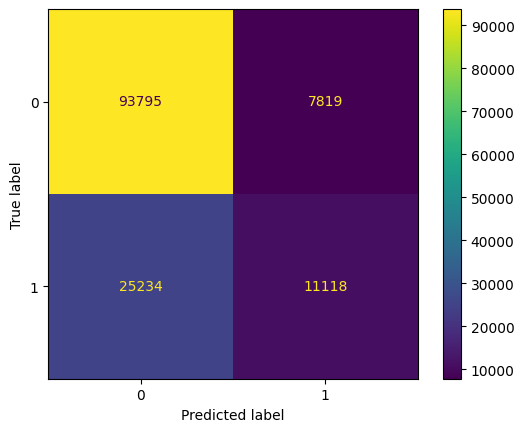

In [20]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.2)
pipe2 = makePipe(numFeatures2, catFeatures)

pipe2.fit(X_train2, y_train2)
predictions2 = pipe2.predict(X_test2)
accuracy2 = (predictions2 == y_test2).mean()
print(f"Model with distance feature accuracy: {accuracy2:.4f}")
# confusion matrix
cm2 = confusion_matrix(y_test2, predictions2)
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm2, display_labels=pipe2.classes_)
disp2.plot()

### Feature Construction - Aggregation

We can also use the spatial data to construct features that are aggregated over some region. For example, we can count the number of infractions within each neighborhood, and use that as a feature in our model.

This is most useful in a situation like this, where we are taking points and sorting them into groups, like neighborhoods. 

#### Per Neighborhood Prediction

<b>Note:</b> The reality of this prediction is not going to be good. We only have a handful of neighborhoods and just a few, not super relevant, per-neighborhood features to use in the model. If we actually want to use this, we'd need to go find more data that is per-neighborhood and build a reasonable feature set to predict the number of infractions. This is just for the sake of manipulating the spatial data. 

In [21]:
hood_pred_cols = ["hood_geometry", "Row ID", "Name","Was Cannabis Involved", "Officer Initiated"]
hoodDF = df_w_hoods[hood_pred_cols].dropna(subset=hood_pred_cols)
hoodDF.set_geometry("hood_geometry", inplace=True)
hoodDF["Was Cannabis Involved"] = hoodDF["Was Cannabis Involved"].map({"Yes": 1, "No": 0})
hoodDF["Officer Initiated"] = hoodDF["Officer Initiated"].map({"Yes": 1, "No": 0})
hoodDF = hoodDF.groupby("Name").agg({"Row ID": "count", "Was Cannabis Involved": "sum", "Officer Initiated": "sum"}).rename(columns={"Row ID": "Count"}).sort_values(by="Count", ascending=False)
hoodDF = hoodDF.reset_index()
hoodDF = hoodDF.join(gdf_hoods_mercator.set_index("Name")[["geometry"]], on="Name", how="left")
hoodDF = gpd.GeoDataFrame(hoodDF, geometry="geometry", crs=gdf_hoods_mercator.crs)
hoodDF.head()

,Name,Count,Was Cannabis Involved,Officer Initiated,geometry
0,ALBERTA AVENUE,15350,0.0,0.0,"MULTIPOLYGON (((-12633900.296 7090376.857, -12..."
1,DOWNTOWN,14708,0.0,0.0,"MULTIPOLYGON (((-12636109.257 7083797.966, -12..."
2,MCCAULEY,13902,0.0,0.0,"MULTIPOLYGON (((-12633409.49 7085026.777, -126..."
3,OLIVER,11304,0.0,0.0,"MULTIPOLYGON (((-12635857.069 7083575.54, -126..."
4,STRATHCONA,9737,0.0,0.0,"MULTIPOLYGON (((-12632393.744 7080398.944, -12..."


In [22]:
hoodDF["Area"] = hoodDF.area
hoodDF["Circumference"] = hoodDF.length
hoodDF["Compactness"] = hoodDF["Circumference"] / hoodDF["Area"]
hoodDF["Closest Station Distance"] = hoodDF.apply(lambda row: getClosestStationDistance(row, stations), axis=1)
hoodDF.sort_values("Closest Station Distance", ascending=True).head()

,Name,Count,Was Cannabis Involved,Officer Initiated,geometry,Area,Circumference,Compactness,Closest Station Distance
22,BOYLE STREET,5067,0.0,0.0,"MULTIPOLYGON (((-12632857.787 7085275.807, -12...",2.492290e+06,8513.657279,0.003416,0.0
19,WINDERMERE,5322,0.0,0.0,"MULTIPOLYGON (((-12646458.09 7066240.088, -126...",1.342701e+07,23872.391738,0.001778,0.0
17,GLENWOOD,5795,0.0,0.0,"MULTIPOLYGON (((-12647591.852 7083051.301, -12...",5.009729e+06,9128.915350,0.001822,0.0
187,MILLER,1226,0.0,0.0,"MULTIPOLYGON (((-12625533.883 7096405.94, -126...",2.344929e+06,6976.331325,0.002975,0.0
69,KENSINGTON,2751,0.0,0.0,"MULTIPOLYGON (((-12638652.398 7094659.62, -126...",3.756222e+06,8211.492371,0.002186,0.0


<Axes: >

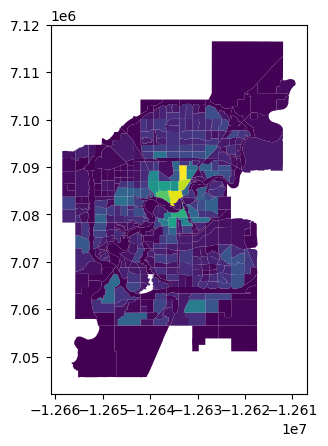

In [23]:
hoodDF.plot("Count")

In [24]:
hoodPredCols = ["Area", "Closest Station Distance", "Was Cannabis Involved", "Officer Initiated"]
yHoods = hoodDF["Count"]
Xhoods = hoodDF[hoodPredCols]

X_trainH, X_testH, y_trainH, y_testH = train_test_split(Xhoods, yHoods, test_size=0.2)

In [25]:
pipeHood = makePipe(hoodPredCols, [], doRegression=True)

pipeHood.fit(X_trainH, y_trainH)
hoodPreds = pipeHood.predict(X_testH)
hoodScore = pipeHood.score(X_testH, y_testH)
print(f"Hood model R^2 score: {hoodScore:.4f}")

Hood model R^2 score: 0.0408


### Feature Construction - Things Within

Another type of feature that is useful is to count the number of things within some distance. For the "within" part we can either define a buffer, which is basically a virtual circle N-distance from another point (or geometry), or we can use an existing poylgon like a neighborhood. In code, this is pretty simple, as long as we have geomerties defined, the 'within' function will do the work for us.

#### Buffers and Density Calculations

Let's try adding a feature to the dataset that measures the relative density of infractions. Since we want this on a per-infraction basis, we want to decide on a way to measure how many other infractions are "nearby". This is 100% arbitrary, we'd need some domain knowledge to make actual real decisions of what "nearby" means. 

In [26]:

def infractionsWithin(row, otherEvents, distance=100):
    if row.geometry is None or row.geometry.is_empty:
        return 0
    buffer = row.geometry.buffer(distance)
    count = otherEvents[otherEvents.geometry.within(buffer)].shape[0]
    return count

if DO_WITHIN_BUFF:
    infraction_radius = 100  # meters
    df_w_hoods["infractions_within_radius"] = df_w_hoods.apply(infractionsWithin, axis=1, otherEvents=df_w_hoods, distance=infraction_radius)
df_w_hoods.sort_values("closest_station_distance", ascending=True).head()


,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,...,extrude,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,hood_geometry,closest_station_distance
279952,18074254615345240,2025,12-Dec,"Dec 26, 2025",Property - Snow/Ice,Snow,0,0,Completed,165 STREET NW,...,0.0,-1.0,NaN,None,4180,Glenwood,,,"MULTIPOLYGON (((-12647591.852 7083051.301, -12...",91.048048
15347,13158369737941606,2025,01-Jan,"Jan 15, 2025",Property - Snow/Ice,Ice,0,0,Completed,165 STREET NW,...,0.0,-1.0,NaN,None,4180,Glenwood,,,"MULTIPOLYGON (((-12647591.852 7083051.301, -12...",91.048048
228152,17666759585050930,2024,08-Aug,"Aug 19, 2024",Property - Nuisance,Weeds,0,0,Completed,165 STREET NW,...,0.0,-1.0,NaN,None,4180,Glenwood,,,"MULTIPOLYGON (((-12647591.852 7083051.301, -12...",91.048048
176895,22454509581547448,2024,07-Jul,"Jul 15, 2024",Property - Nuisance,Weeds,0,0,Completed,165 STREET NW,...,0.0,-1.0,NaN,None,4180,Glenwood,,,"MULTIPOLYGON (((-12647591.852 7083051.301, -12...",91.048048
279683,26559697834910976,2024,08-Aug,"Aug 14, 2024",Property - Nuisance,Weeds,0,0,Completed,165 STREET NW,...,0.0,-1.0,NaN,None,4180,Glenwood,,,"MULTIPOLYGON (((-12647591.852 7083051.301, -12...",91.048048


#### Smaller Example - Police Stations Within Buffer

This example is more practial to run, but not as useful. This will take a buffer distance around each point, and tabulate the number of police stations within that buffer. This is one pretty common type of feature we'd create. 

In [27]:
def policeStationsWithin(row, stations_list, distance=1000):
    if row.geometry is None or row.geometry.is_empty:
        return 0
    buffer = row.geometry.buffer(distance)
    count = stations_list[stations_list.geometry.within(buffer)].shape[0]
    return count

df_w_hoods["police_stations_within_radius"] = df_w_hoods.apply(policeStationsWithin, axis=1, stations_list=stations, distance=3000)
df_w_hoods.sort_values("police_stations_within_radius", ascending=False).head()

,Row ID,Year,Month,Date Created,Complaint Category,Type of Complaint,Was Cannabis Involved,Officer Initiated,Infraction Status,Full Name of Street,...,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,hood_geometry,closest_station_distance,police_stations_within_radius
44846,276421021451041728,2026,05-May,"May 12, 2026",Property - Nuisance,Nuisance Property,0,0,Completed,102 STREET NW,...,-1.0,NaN,None,1030,Central McDougall,,,"MULTIPOLYGON (((-12635086.483 7084969.413, -12...",1555.826789,5
676479,114815363421655488,2013,09-Sep,"Sep 09, 2013",Property - Nuisance,Property - Untidy / Unsightly yard,0,1,Completed,110 AVENUE NW,...,-1.0,NaN,None,1140,McCauley,,,"MULTIPOLYGON (((-12633409.49 7085026.777, -126...",1954.087602,5
290179,77362792346621696,2022,04-Apr,"Apr 12, 2022",Business Licensing,Unlicenced business,0,0,Completed,111 AVENUE NW,...,-1.0,NaN,None,1140,McCauley,,,"MULTIPOLYGON (((-12633409.49 7085026.777, -126...",2386.111767,5
379728,3042019064051466,2023,08-Aug,"Aug 21, 2023",Other,Littering,0,0,Completed,108 STREET NW,...,-1.0,NaN,None,1030,Central McDougall,,,"MULTIPOLYGON (((-12635086.483 7084969.413, -12...",1831.390263,5
560133,120340584806120528,2016,10-Oct,"Oct 19, 2016",Property - Nuisance,Nuisance Property,0,1,Completed,95A STREET NW,...,-1.0,NaN,None,1010,Alberta Avenue,,,"MULTIPOLYGON (((-12633900.296 7090376.857, -12...",2340.263920,5


### Model with Police Stations Within Buffer

This is not a great example in terms of feature independence, as we have two metrics that both measure police station distance related things. For using the spatial data though, this is good enough. 

Model with distance and within radius features accuracy: 0.7611


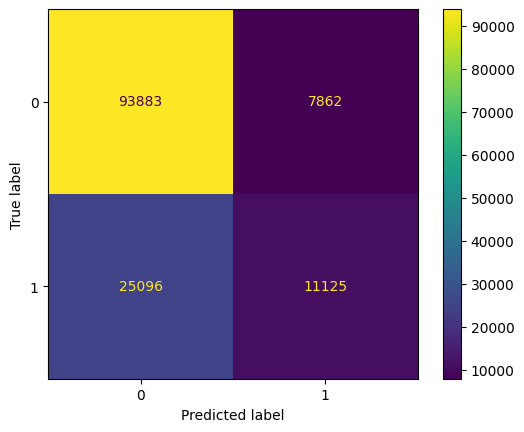

In [28]:
numFeatures3 = numFeatures2 + ["police_stations_within_radius"]

y3 = df_w_hoods[predCol]
X3 = df_w_hoods[numFeatures3 + catFeatures]

Xtrain3, X_test3, y_train3, y_test3 = train_test_split(X3, y3, test_size=0.2)

pipe3 = makePipe(numFeatures3, catFeatures)

pipe3.fit(Xtrain3, y_train3)
predictions3 = pipe3.predict(X_test3)
accuracy3 = (predictions3 == y_test3).mean()
print(f"Model with distance and within radius features accuracy: {accuracy3:.4f}")
# confusion matrix
cm3 = confusion_matrix(y_test3, predictions3)
disp3 = ConfusionMatrixDisplay(confusion_matrix=cm3, display_labels=pipe3.classes_)
disp3.plot()


## Exercise

In [140]:
df_ex2 = pd.read_csv("data/Assessments.csv")
df_ex2 = gpd.GeoDataFrame(df_ex2, geometry=gpd.points_from_xy(df_ex2['Longitude'], df_ex2['Latitude']), crs="EPSG:3776")
df_ex2 = df_ex2.drop(columns=["Latitude", "Longitude"])
df_ex2.head()

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry
0,1066158,NaN,14904.0,167 AVENUE NW,N,NaN,NaN,NaN,86000,POINT (-113.58 53.63)
1,10508233,NaN,16340.0,MARK MESSIER TRAIL NW,N,NaN,NaN,NaN,45000,POINT (-113.606 53.617)
2,1194398,NaN,15617.0,83 STREET NW,N,2050.0,BELLE RIVE,Ward 3,285000,POINT (-113.468 53.617)
3,1034214,NaN,10661.0,161 AVENUE NW,Y,3040.0,BEAUMARIS,Ward 3,635000,POINT (-113.507 53.62)
4,1114701,NaN,15003.0,76 AVENUE NW,Y,4430.0,RIO TERRACE,Ward 5,407500,POINT (-113.58 53.509)


In [150]:
left_join_col = "Neighbourhood"
right_join_col = "Name"

hood_area = gdf_hoods.to_crs(epsg=3776).geometry.area
area_by_hood = pd.Series(hood_area.to_numpy(), index=gdf_hoods[right_join_col]).to_dict()
df_ex2["Area"] = df_ex2[left_join_col].map(area_by_hood)
df_ex2.head()

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry,...,visibility,drawOrder,icon,neighbourhood_number,descriptive_name,effective_start_date,effective_end_date,Hood Geometry,Name_y,Area
0,1066158,NaN,14904.0,167 AVENUE NW,N,NaN,NaN,NaN,86000,POINT (-113.58 53.63),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN
1,10508233,NaN,16340.0,MARK MESSIER TRAIL NW,N,NaN,NaN,NaN,45000,POINT (-113.606 53.617),...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN
2,1194398,NaN,15617.0,83 STREET NW,N,2050.0,BELLE RIVE,Ward 3,285000,POINT (-113.468 53.617),...,-1.0,NaN,None,2050,Belle Rive,,,"MULTIPOLYGON (((-113.4797 53.61859, -113.4797 ...",BELLE RIVE,1.173439e+06
3,1034214,NaN,10661.0,161 AVENUE NW,Y,3040.0,BEAUMARIS,Ward 3,635000,POINT (-113.507 53.62),...,-1.0,NaN,None,3040,Beaumaris,,,"MULTIPOLYGON (((-113.51874 53.62281, -113.5190...",BEAUMARIS,1.439967e+06
4,1114701,NaN,15003.0,76 AVENUE NW,Y,4430.0,RIO TERRACE,Ward 5,407500,POINT (-113.58 53.509),...,-1.0,NaN,None,4430,Rio Terrace,,,"MULTIPOLYGON (((-113.58989 53.50276, -113.5897...",RIO TERRACE,5.827518e+05


In [151]:
df_ex2.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 384217 entries, 0 to 384216
Data columns (total 28 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Account Number        384217 non-null  int64         
 1   Suite                 80043 non-null   object        
 2   House Number          342008 non-null  float64       
 3   Street Name           342008 non-null  object        
 4   Garage                384217 non-null  object        
 5   Neighbourhood ID      384213 non-null  float64       
 6   Neighbourhood         384213 non-null  object        
 7   Ward                  384213 non-null  object        
 8   Assessed Value        384217 non-null  int64         
 9   geometry              384217 non-null  geometry      
 10  Name_x                384213 non-null  object        
 11  description           384213 non-null  object        
 12  timestamp             0 non-null       datetime64[

In [152]:
edm_centre_cord_point = gpd.GeoSeries([gpd.points_from_xy([-113.4903], [53.5344])[0]], crs="EPSG:3776")

In [196]:
def addHousingDensity(listHomes, neighbourhoodCol = "Neighbourhood", areaCol="Area"):
    # Calculate the number of homes in each neighbourhood
    home_counts = listHomes.groupby(neighbourhoodCol).size()
    
    # Create a dictionary mapping neighbourhoods to their areas
    area_by_hood = pd.Series(listHomes[areaCol].values, index=listHomes[neighbourhoodCol]).to_dict()
    
    # Calculate housing density for each neighbourhood
    housing_density = {hood: home_counts.get(hood, 0) / area_by_hood.get(hood, 1) for hood in area_by_hood.keys()}
    
    # Map the housing density back to the original DataFrame
    listHomes["Housing Density"] = listHomes[neighbourhoodCol].map(housing_density)
    
    return listHomes

df_ex2 = addHousingDensity(df_ex2)
df_ex2["dist_centre"] = df_ex2.geometry.distance(edm_centre_cord_point.iloc[0])*1000
df_ex2 = df_ex2[df_ex2["dist_centre"] < 20]
df_ex2.sort_values("dist_centre", ascending=False)

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry,...,descriptive_name,effective_start_date,effective_end_date,Hood Geometry,Name_y,Area,Hood Density,Housing Density,dist_centre,Is Suite
52399,3767803,NaN,10369.0,93 STREET NW,Y,1020.0,BOYLE STREET,Ward 6,0.601141,POINT (-113.477 53.549),...,Boyle Street,,,"MULTIPOLYGON (((-113.48289 53.5494, -113.48307...",BOYLE STREET,8.813511e+05,NaN,0.000590,19.997632,False
142622,8277709,NaN,9518.0,DONNELL ROAD NW,N,6710.0,STRATHEARN,Ward 8,0.606200,POINT (-113.47 53.532),...,Strathearn,,,"MULTIPOLYGON (((-113.47155 53.53287, -113.4717...",STRATHEARN,7.862926e+05,NaN,0.000022,19.995638,False
68913,3828076,NaN,10040.0,92 STREET NW,N,1210.0,RIVERDALE,Ward 6,0.602859,POINT (-113.472 53.543),...,Riverdale,,,"MULTIPOLYGON (((-113.48874 53.53854, -113.4884...",RIVERDALE,1.068520e+06,NaN,0.000389,19.995445,False
57754,3619707,NaN,10844.0,98 STREET NW,N,1140.0,MCCAULEY,Ward 6,0.599781,POINT (-113.492 53.554),...,McCauley,,,"MULTIPOLYGON (((-113.48785 53.54807, -113.4876...",MCCAULEY,1.498158e+06,NaN,0.000111,19.995222,False
144084,8228124,NaN,9621.0,83 AVENUE NW,Y,5480.0,STRATHCONA,Ward 8,0.604477,POINT (-113.478 53.519),...,Strathcona,,,"MULTIPOLYGON (((-113.47872 53.52336, -113.4788...",STRATHCONA,1.563266e+06,NaN,0.002385,19.989477,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56727,3183142,NaN,9654.0,100 STREET NW,N,1220.0,ROSSDALE,Ward 6,0.605705,POINT (-113.491 53.534),...,Rossdale,,,"MULTIPOLYGON (((-113.50127 53.53078, -113.5012...",ROSSDALE,9.031368e+05,NaN,0.000495,1.281987,False
48579,3728920,NaN,10010.0,97 AVENUE NW,Y,1220.0,ROSSDALE,Ward 6,0.605314,POINT (-113.491 53.534),...,Rossdale,,,"MULTIPOLYGON (((-113.50127 53.53078, -113.5012...",ROSSDALE,9.031368e+05,NaN,0.000495,1.185674,False
53642,3728938,NaN,10008.0,97 AVENUE NW,Y,1220.0,ROSSDALE,Ward 6,0.605378,POINT (-113.491 53.535),...,Rossdale,,,"MULTIPOLYGON (((-113.50127 53.53078, -113.5012...",ROSSDALE,9.031368e+05,NaN,0.000495,1.077224,False
61069,3728946,NaN,10006.0,97 AVENUE NW,Y,1220.0,ROSSDALE,Ward 6,0.605018,POINT (-113.491 53.535),...,Rossdale,,,"MULTIPOLYGON (((-113.50127 53.53078, -113.5012...",ROSSDALE,9.031368e+05,NaN,0.000495,0.974748,False


In [197]:
df_ex2["Is Suite"] = df_ex2["Suite"].notnull().astype(object)
df_ex2.head()

,Account Number,Suite,House Number,Street Name,Garage,Neighbourhood ID,Neighbourhood,Ward,Assessed Value,geometry,...,descriptive_name,effective_start_date,effective_end_date,Hood Geometry,Name_y,Area,Hood Density,Housing Density,dist_centre,Is Suite
27,1177625,1603,10135.0,SASKATCHEWAN DRIVE NW,N,5480.0,STRATHCONA,Ward 8,0.599658,POINT (-113.493 53.524),...,Strathcona,,,"MULTIPOLYGON (((-113.47872 53.52336, -113.4788...",STRATHCONA,1.563266e+06,NaN,0.002385,10.495052,True
28,1309699,301,10033.0,89 AVENUE NW,N,5480.0,STRATHCONA,Ward 8,0.601029,POINT (-113.49 53.524),...,Strathcona,,,"MULTIPOLYGON (((-113.47872 53.52336, -113.4788...",STRATHCONA,1.563266e+06,NaN,0.002385,10.193033,True
38,1210673,203,9860.0,82 AVENUE NW,N,5480.0,STRATHCONA,Ward 8,0.597552,POINT (-113.485 53.518),...,Strathcona,,,"MULTIPOLYGON (((-113.47872 53.52336, -113.4788...",STRATHCONA,1.563266e+06,NaN,0.002385,16.888411,True
86,1178581,NaN,NaN,NaN,N,5480.0,STRATHCONA,Ward 8,0.579907,POINT (-113.493 53.524),...,Strathcona,,,"MULTIPOLYGON (((-113.47872 53.52336, -113.4788...",STRATHCONA,1.563266e+06,NaN,0.002385,10.495052,False
139,1234863,1506,10149.0,SASKATCHEWAN DRIVE NW,N,5480.0,STRATHCONA,Ward 8,0.599473,POINT (-113.494 53.523),...,Strathcona,,,"MULTIPOLYGON (((-113.47872 53.52336, -113.4788...",STRATHCONA,1.563266e+06,NaN,0.002385,11.471201,True


In [198]:
df_ex2.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 16601 entries, 27 to 384213
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Account Number        16601 non-null  int64         
 1   Suite                 8243 non-null   object        
 2   House Number          10570 non-null  float64       
 3   Street Name           10570 non-null  object        
 4   Garage                16601 non-null  object        
 5   Neighbourhood ID      16601 non-null  float64       
 6   Neighbourhood         16601 non-null  object        
 7   Ward                  16601 non-null  object        
 8   Assessed Value        16601 non-null  float64       
 9   geometry              16601 non-null  geometry      
 10  Name_x                16601 non-null  object        
 11  description           16601 non-null  object        
 12  timestamp             0 non-null      datetime64[ms]
 13  begin      

I got a pretty big variance in the scores if I included Neighborhood as a feature, which makes sense, since there is a large number of them and not *that* much data. The average 'good' run usually got an R2 around .6 or a bit higher, but it was pretty random. That's pretty normal with smaller samples, we get big swings - that shrinks as data grows. What could we do to help ourselves with small samples...

In [218]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error
ex2_num_col = ["Area", "dist_centre", "Housing Density"]
ex2_cat_col = ["Garage", "Ward"]

#Try Both! Or None
ex2_cat_col = ex2_cat_col+["Neighbourhood"]
ex2_cat_col = ex2_cat_col+["Is Suite"]

# There are some outliers, so I'll try filtering
df_ex2 = df_ex2[df_ex2["Assessed Value"] < 1000000]
# Optional log transform to reduce skewness
LOG_TRANSFORM = True
if LOG_TRANSFORM:
    df_ex2["Assessed Value"] = np.log1p(df_ex2["Assessed Value"])

yex2 = df_ex2["Assessed Value"]
Xex2 = df_ex2[ex2_num_col + ex2_cat_col]

X_ex2_train, X_ex2_test, y_ex2_train, y_ex2_test = train_test_split(Xex2, yex2, test_size=0.2)

pipe_ex2 = makePipe(ex2_num_col, ex2_cat_col, doRegression=True)

pipe_ex2.fit(X_ex2_train, y_ex2_train)
predictions_ex2 = pipe_ex2.predict(X_ex2_test)
ex2_score = pipe_ex2.score(X_ex2_test, y_ex2_test)

print(f"Assessment model R^2 score: {ex2_score:.4f}")

Assessment model R^2 score: 0.1041
